In [1]:
from torchvision.datasets import MNIST

train_data = MNIST(root="./data", train=True, download=True, transform=None)
test_data = MNIST(root="./data", train=False, download=True, transform=None)

100%|██████████| 9.91M/9.91M [00:03<00:00, 3.06MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.56MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 240kB/s]


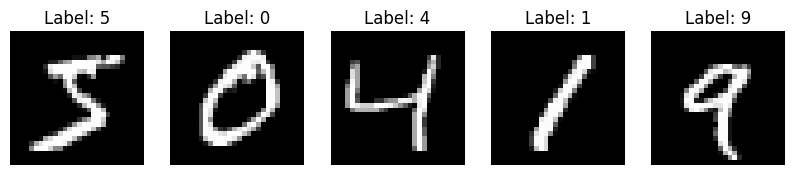

In [2]:
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
from torchvision.datasets import MNIST

transform = transforms.Compose(
    [
        transforms.ToTensor(),  # из [0,255] в [0,1]
        transforms.Normalize(
            (0.1307,), (0.3081,)
        ),  # нормализация (mean=0.1307,std=0.3081)
        # Значения вычислены по всему тренировочному набору MNIST и помогают привести данные к нулевому среднему и единичному стандартному отклонению, что ускоряет и стабилизирует обучение.
    ]
)


train_data = MNIST(root="./data", train=True, download=True, transform=transform)
test_data = MNIST(root="./data", train=False, download=True, transform=transform)


# Блок кода, отвечающий за визуализацию, его редактировать не надо.
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    img, label = train_data[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.show()

In [3]:
from torch.utils.data import random_split

train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size

train_data, val_data = random_split(train_data, [train_size, val_size])

images.shape: torch.Size([64, 1, 28, 28])
labels.shape: torch.Size([64])
Метка первого изображения в батче: 5


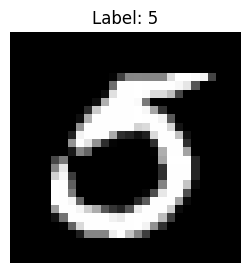

In [4]:
from torch.utils.data import DataLoader

transform = transforms.Compose(
    [
        transforms.ToTensor(),  # из [0,255] в [0,1]
        transforms.Normalize(
            (0.1307,), (0.3081,)
        ),  # нормализация (mean=0.1307,std=0.3081)
    ]
)


train_data = MNIST(root="./data", train=True, download=True, transform=transform)
test_data = MNIST(root="./data", train=False, download=True, transform=transform)


train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size

train_data, val_data = random_split(train_data, [train_size, val_size])


train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)


images, labels = next(iter(train_loader))


# Печатаем формы тензоров
print("images.shape:", images.shape)  # torch.Size([64, 1, 28, 28])
print("labels.shape:", labels.shape)  # torch.Size([64])


# Выведем метку первого изображения
first_label = labels[0].item()
print("Метка первого изображения в батче:", first_label)


# Отобразим само первое изображение
plt.figure(figsize=(3, 3))
plt.imshow(images[0].squeeze(), cmap="gray")
plt.title(f"Label: {first_label}")
plt.axis("off")
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.init as init
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import MNIST

# Готовим данные
transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]
)


# Подготовка данных из прошлого урока
dataset = MNIST(root="./data", train=True, download=True, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_data, val_data = random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
images, labels = next(iter(train_loader))


# Определяем модель через nn.Sequential

model_seq = nn.Sequential(
    nn.Flatten(),  # развернёт картинку 1×28×28 → 784
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)  # Ваш код здесь


# Прогон и обучение одного батча
out_seq = model_seq(images)
print("Output shape:", out_seq.shape)  # ожидаем [64, 10]


# Оптимизатор и функция потерь
# Ваш код здесь
optimizer = torch.optim.SGD(model_seq.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()


# Прямой проход
optimizer.zero_grad()
# Ваш код здесь
loss = criterion(out_seq, labels)
loss.backward()
optimizer.step()

print("Loss после одного шага:", loss.item())

Output shape: torch.Size([64, 10])
Loss после одного шага: 2.30716872215271


In [11]:
# Реализация класса
class AdvancedMNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        # Определите слои:
        #   Linear(784→256), BatchNorm1d(256), ReLU, Dropout(0.5),
        #   Linear(256→128), ReLU, Linear(128→10)
        self.linear1 = nn.Linear(784, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.linear2 = nn.Linear(256, 128)
        self.linear3 = nn.Linear(128, 10)

        # Инициализация Xavier
        for layer in (self.linear1, self.linear2, self.linear3):
            init.xavier_uniform_(layer.weight)
            layer.bias.data.zero_()

    def forward(self, x):
        # Разворачиваем изображение (batch,1,28,28) → (batch,784)
        x = x.view(x.size(0), -1)
        x = self.linear1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.linear2(x)
        x = self.relu(x)
        x = self.linear3(x)
        return x


# Загрузка данных и DataLoader

transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]
)
train_data = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)


# Один батч и прямой проход
model = AdvancedMNISTMLP()


images, labels = next(iter(train_loader))


outputs = model(images)


# Вывод результатов
print("Output shape:", outputs.shape)  # ожидаем [64, 10]
print("Batch labels shape:", labels.shape)  # [64]

Output shape: torch.Size([64, 10])
Batch labels shape: torch.Size([64])


In [10]:
class AdvancedMNISTMLPSeq(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )
        for m in self.net:
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                m.bias.data.zero_()

    def forward(self, x):
        return self.net(x)


# Загрузка данных и DataLoader
transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]
)
train_data = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

# Один батч и прямой проход
model = AdvancedMNISTMLPSeq()

images, labels = next(iter(train_loader))

outputs = model(images)

# Вывод результатов
print("Output shape:", outputs.shape)  # ожидаем [64, 10]
print("Batch labels shape:", labels.shape)  # [64]

Output shape: torch.Size([64, 10])
Batch labels shape: torch.Size([64])


In [8]:
class FlexibleMNISTMLP(nn.Module):
    def __init__(self, hidden_sizes=(256, 128), dropout_p=0.5):
        super().__init__()
        self.flatten = nn.Flatten()

        layers = []
        in_dim = 784
        for h in hidden_sizes:
            layers.append(nn.Linear(in_dim, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_p))
            in_dim = h

        self.hidden = nn.ModuleList(layers)
        self.output = nn.Linear(in_dim, 10)

        for m in self.hidden:
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                m.bias.data.zero_()
        init.xavier_uniform_(self.output.weight)
        self.output.bias.data.zero_()

    def forward(self, x):
        x = self.flatten(x)
        for layer in self.hidden:
            x = layer(x)
        x = self.output(x)
        return x


transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]
)
train_data = MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

model = FlexibleMNISTMLP(hidden_sizes=[256, 128], dropout_p=0.5)

images, labels = next(iter(train_loader))
outputs = model(images)

print("Output shape:", outputs.shape)
print("Batch labels shape:", labels.shape)
print("Число скрытых модулей:", len(model.hidden))

model_deep = FlexibleMNISTMLP(hidden_sizes=[512, 256, 128, 64])
outputs_deep = model_deep(images)
print("\nГлубокая модель — Output shape:", outputs_deep.shape)
print("Число скрытых модулей:", len(model_deep.hidden))

Output shape: torch.Size([64, 10])
Batch labels shape: torch.Size([64])
Число скрытых модулей: 6

Глубокая модель — Output shape: torch.Size([64, 10])
Число скрытых модулей: 12


Epoch 1/5 — Loss: 0.3469, Accuracy: 90.12%
Epoch 2/5 — Loss: 0.1396, Accuracy: 95.84%
Epoch 3/5 — Loss: 0.0954, Accuracy: 97.14%
Epoch 4/5 — Loss: 0.0699, Accuracy: 97.90%
Epoch 5/5 — Loss: 0.0544, Accuracy: 98.32%
Test Loss: 0.0803, Test Accuracy: 97.33%


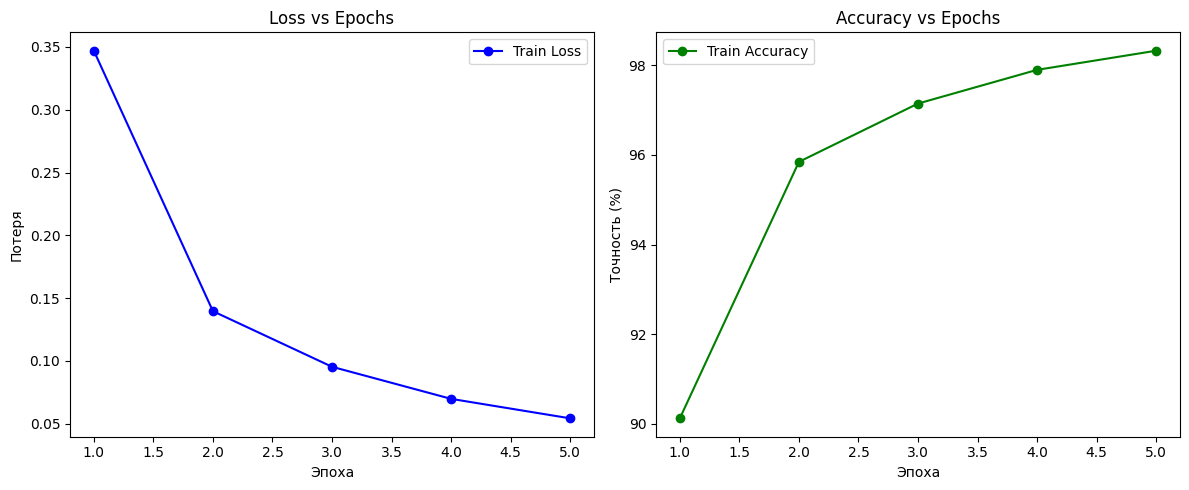

In [13]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


# Определяем модель AdvancedMNISTMLPList (из прошлого урока)
class AdvancedMNISTMLPList(nn.Module):
    def __init__(self):
        super(AdvancedMNISTMLPList, self).__init__()
        self.layers = nn.ModuleList(
            [
                nn.Linear(28 * 28, 128),
                nn.ReLU(),
                nn.Linear(128, 64),
                nn.ReLU(),
                nn.Linear(64, 10),
            ]
        )

    def forward(self, x):
        x = x.view(-1, 28 * 28)  # раскладываем картинку в вектор
        for layer in self.layers:
            x = layer(x)
        return x


model = AdvancedMNISTMLPList()


# Загружаем данные MNIST (тренировочный и тестовый набор)
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(
    root="./data", train=True, download=False, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=False, transform=transform
)


train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)


# Инициализируем функцию потерь и оптимизатор
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


# Цикл обучения
num_epochs = 5

train_losses = []
train_accuracies = []


for epoch in range(num_epochs):
    model.train()  # перевод модели в режим обучения
    running_loss = 0.0
    correct = 0
    total = 0

    # Проход по всем батчам трен.набора
    for images, labels in train_loader:
        # Прямой проход
        outputs = model(images)  # выходы - логиты [batch, 10]
        loss = criterion(outputs, labels)  # вычисляем потерю

        # Обратный проход и оптимизация
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Накопление статистики для метрик
        running_loss += loss.item()  # суммируем loss
        _, predicted = outputs.max(
            1
        )  # индекс максимальной логиты = предсказанный класс
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    # Средние значения по эпохе
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100.0 * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    # Выводим информацию по эпохе
    print(
        f"Epoch {epoch + 1}/{num_epochs} — Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%"
    )


# Оценка на тестовом наборе
model.eval()  # режим оценки
test_loss = 0.0

correct = 0

total = 0

all_preds = []
all_labels = []


with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


test_loss = test_loss / len(test_loader)
test_accuracy = 100.0 * correct / total

print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")


# Построение графиков потерь и точности
epochs = range(1, num_epochs + 1)
plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", color="blue", label="Train Loss")
plt.title("Loss vs Epochs")
plt.xlabel("Эпоха")
plt.ylabel("Потеря")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", color="green", label="Train Accuracy")
plt.title("Accuracy vs Epochs")
plt.xlabel("Эпоха")
plt.ylabel("Точность (%)")
plt.legend()


plt.tight_layout()
plt.show()

MLP_1layer Epoch 1/5 - Train Loss: 0.4148, Val Loss: 0.2526, Val Acc: 92.67%
MLP_1layer Epoch 2/5 - Train Loss: 0.2360, Val Loss: 0.2204, Val Acc: 93.67%
MLP_1layer Epoch 3/5 - Train Loss: 0.2006, Val Loss: 0.1869, Val Acc: 94.48%
MLP_1layer Epoch 4/5 - Train Loss: 0.1793, Val Loss: 0.1749, Val Acc: 94.76%
MLP_1layer Epoch 5/5 - Train Loss: 0.1660, Val Loss: 0.1779, Val Acc: 94.77%


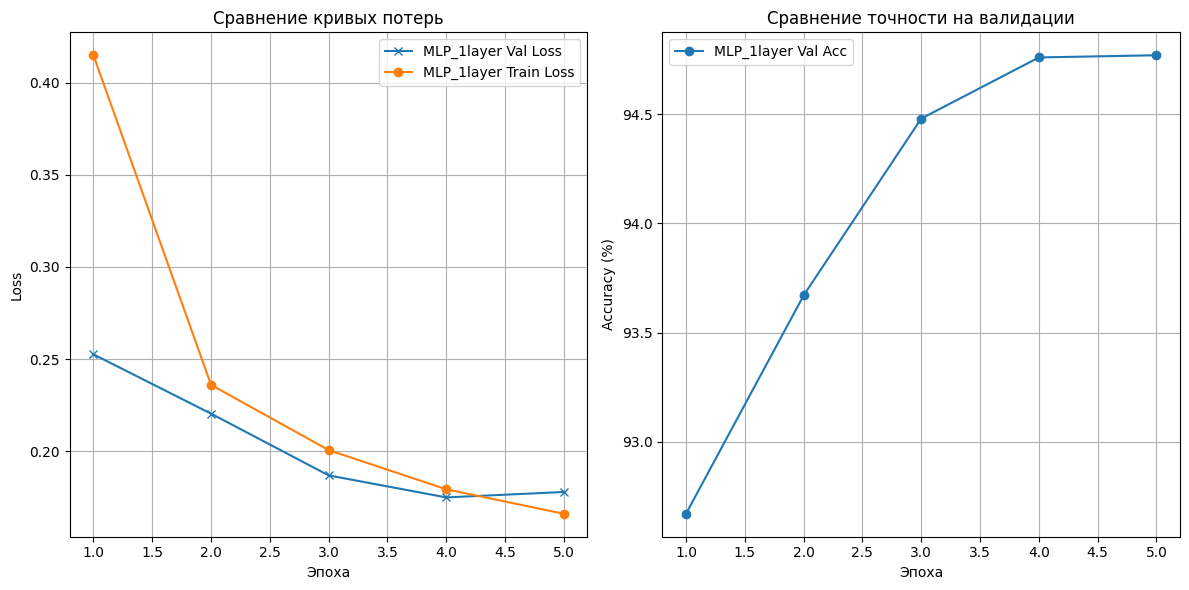

In [14]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Подготовка данных MNIST

transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]
)
train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
val_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1000, shuffle=False)


# Последовательность самой модели
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 16), nn.ReLU(), nn.Linear(16, 10))


# Название модели для отображения графиков и логирования
name = "MLP_1layer"


num_epochs = 5

hist = {name: {"train_loss": [], "val_loss": [], "val_acc": []}}


criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)


for epoch in range(1, num_epochs + 1):
    # Обучение
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_train_loss = running_loss / len(train_loader)
    # Добавляем потерю для графика
    hist[name]["train_loss"].append(epoch_train_loss)

    # Валидация
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    # В этот раз посчитаем валидацию на каждой эпохе обучения
    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = 100.0 * correct / total
    # Добавляем потерю для графика
    hist[name]["val_loss"].append(epoch_val_loss)
    # Добавляем точность для графика
    hist[name]["val_acc"].append(epoch_val_acc)

    print(
        f"{name} Epoch {epoch}/{num_epochs} - "
        f"Train Loss: {epoch_train_loss:.4f}, "
        f"Val Loss: {epoch_val_loss:.4f}, "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )


# Визуализация истории обучения (пример для loss)
plt.figure(figsize=(12, 6))


# Потеря
plt.subplot(1, 2, 1)
epochs = range(1, num_epochs + 1)
plt.plot(epochs, hist[name]["val_loss"], marker="x", label=f"{name} Val Loss")
plt.plot(
    epochs,
    hist[name]["train_loss"],
    marker="o",
    label=f"{name} Train Loss",
)
plt.title("Сравнение кривых потерь")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


# Точность
plt.subplot(1, 2, 2)


epochs = range(1, num_epochs + 1)
plt.plot(epochs, hist[name]["val_acc"], marker="o", label=f"{name} Val Acc")
plt.title("Сравнение точности на валидации")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)


plt.tight_layout()
plt.show()

MLP_2layer Epoch 1/5 - Train Loss: 0.2758, Val Loss: 0.1356, Val Acc: 95.92%
MLP_2layer Epoch 2/5 - Train Loss: 0.1115, Val Loss: 0.1014, Val Acc: 96.94%
MLP_2layer Epoch 3/5 - Train Loss: 0.0765, Val Loss: 0.0857, Val Acc: 97.26%
MLP_2layer Epoch 4/5 - Train Loss: 0.0584, Val Loss: 0.0939, Val Acc: 97.16%
MLP_2layer Epoch 5/5 - Train Loss: 0.0476, Val Loss: 0.0845, Val Acc: 97.45%


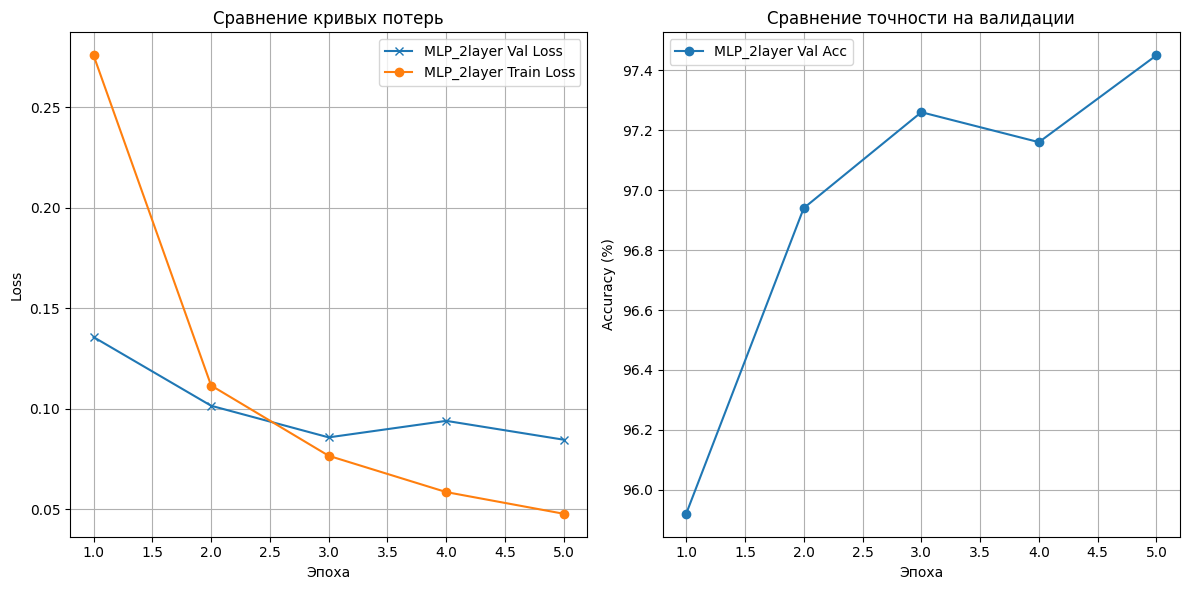

In [15]:
# Последовательность самой модели

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)


# Название модели для отображения графиков и логирования
name = "MLP_2layer"


num_epochs = 5

hist = {name: {"train_loss": [], "val_loss": [], "val_acc": []}}


criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)


for epoch in range(1, num_epochs + 1):
    # Обучение
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_train_loss = running_loss / len(train_loader)
    # Добавляем потерю для графика
    hist[name]["train_loss"].append(epoch_train_loss)

    # Валидация
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    # В этот раз посчитаем валидацию на каждой эпохе обучения
    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = 100.0 * correct / total
    # Добавляем потерю для графика
    hist[name]["val_loss"].append(epoch_val_loss)
    # Добавляем точность для графика
    hist[name]["val_acc"].append(epoch_val_acc)

    print(
        f"{name} Epoch {epoch}/{num_epochs} - "
        f"Train Loss: {epoch_train_loss:.4f}, "
        f"Val Loss: {epoch_val_loss:.4f}, "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )


# Визуализация истории обучения (пример для loss)
plt.figure(figsize=(12, 6))


# Потеря
plt.subplot(1, 2, 1)
epochs = range(1, num_epochs + 1)
plt.plot(epochs, hist[name]["val_loss"], marker="x", label=f"{name} Val Loss")
plt.plot(
    epochs,
    hist[name]["train_loss"],
    marker="o",
    label=f"{name} Train Loss",
)
plt.title("Сравнение кривых потерь")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


# Точность
plt.subplot(1, 2, 2)


epochs = range(1, num_epochs + 1)
plt.plot(epochs, hist[name]["val_acc"], marker="o", label=f"{name} Val Acc")
plt.title("Сравнение точности на валидации")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)


plt.tight_layout()
plt.show()

MLP_3layer Epoch 1/5 - Train Loss: 0.3411, Val Loss: 0.1362, Val Acc: 95.83%
MLP_3layer Epoch 2/5 - Train Loss: 0.1826, Val Loss: 0.0993, Val Acc: 96.93%
MLP_3layer Epoch 3/5 - Train Loss: 0.1501, Val Loss: 0.0957, Val Acc: 96.95%
MLP_3layer Epoch 4/5 - Train Loss: 0.1319, Val Loss: 0.0789, Val Acc: 97.62%
MLP_3layer Epoch 5/5 - Train Loss: 0.1185, Val Loss: 0.0815, Val Acc: 97.54%


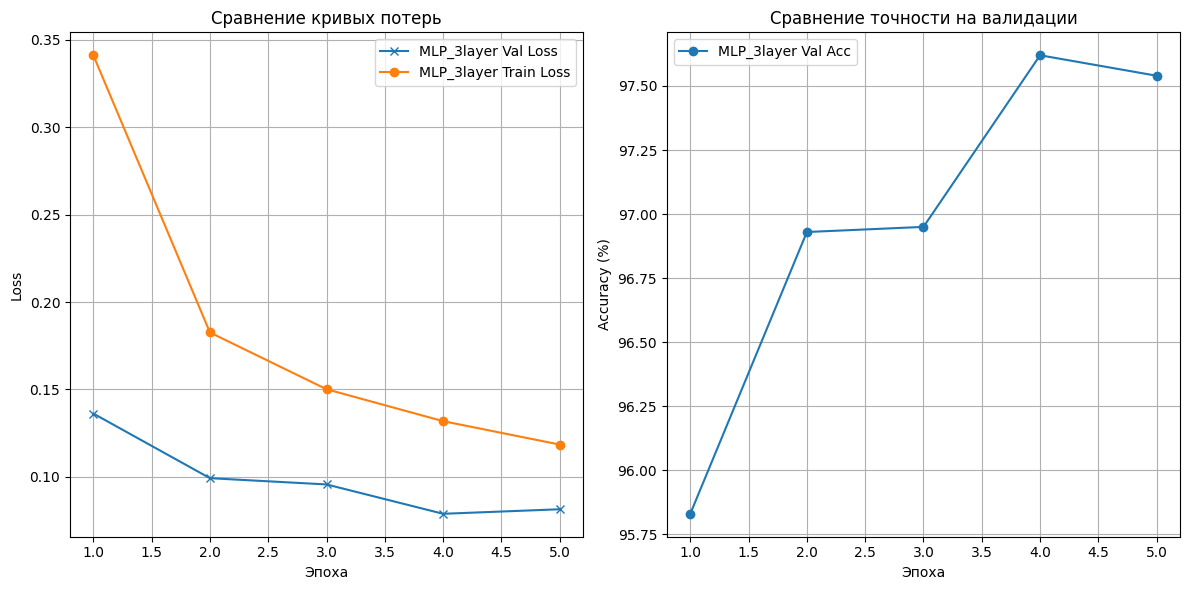

In [16]:
# Последовательность самой модели
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)


# Название модели для отображения графиков и логирования
name = "MLP_3layer"


num_epochs = 5

hist = {name: {"train_loss": [], "val_loss": [], "val_acc": []}}


criterion = nn.CrossEntropyLoss()


optimizer = optim.Adam(model.parameters(), lr=0.001)


for epoch in range(1, num_epochs + 1):
    # Обучение
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_train_loss = running_loss / len(train_loader)
    # Добавляем потерю для графика
    hist[name]["train_loss"].append(epoch_train_loss)

    # Валидация
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    # В этот раз посчитаем валидацию на каждой эпохе обучения
    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = 100.0 * correct / total
    # Добавляем потерю для графика
    hist[name]["val_loss"].append(epoch_val_loss)
    # Добавляем точность для графика
    hist[name]["val_acc"].append(epoch_val_acc)

    print(
        f"{name} Epoch {epoch}/{num_epochs} - "
        f"Train Loss: {epoch_train_loss:.4f}, "
        f"Val Loss: {epoch_val_loss:.4f}, "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )


# Визуализация истории обучения (пример для loss)
plt.figure(figsize=(12, 6))


# Потеря
plt.subplot(1, 2, 1)
epochs = range(1, num_epochs + 1)
plt.plot(epochs, hist[name]["val_loss"], marker="x", label=f"{name} Val Loss")
plt.plot(
    epochs,
    hist[name]["train_loss"],
    marker="o",
    label=f"{name} Train Loss",
)
plt.title("Сравнение кривых потерь")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


# Точность
plt.subplot(1, 2, 2)


epochs = range(1, num_epochs + 1)
plt.plot(epochs, hist[name]["val_acc"], marker="o", label=f"{name} Val Acc")
plt.title("Сравнение точности на валидации")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)


plt.tight_layout()
plt.show()